# 01 — Source Data Survey & Cleaning

| Section | Task | Output |
|---|---|---|
| 1 | Load and verify the dataset | Source, version, provenance |
| 2 | Shape, types, missing values, duplicates, validity | Data audit |
| 3 | Missing values, duplicates, formatting, outliers, logic | `data/processed/bookings_city_clean.csv` + cleaning log (3.6) |
| 4 | Scale of the problem, key drivers, cancellation timing | Preliminary EDA |
| 5 | What the dataset lacks for revenue & occupancy decisions | Data gap analysis |

> `hotel_bookings.csv` is read-only. The cleaned file keeps all 79,330 City Hotel rows. Suspicious rows are **flagged** (`is_duplicate`, `exclude_from_model`), never silently dropped. Deep EDA and feature engineering are in notebook 03.

## 0. Setup

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Locate the project root (works whether the notebook runs from /notebooks or the root)
ROOT = Path.cwd()
while not (ROOT / "hotel_bookings.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_PATH = ROOT / "hotel_bookings.csv"
assert DATA_PATH.exists(), "hotel_bookings.csv not found — run from inside the project repo"
DATA_PATH

WindowsPath('C:/Users/ADMIN/Desktop/AAA/BA-Advance-Project---Group-2-main/hotel_bookings.csv')

## 1. Load and verify the dataset

### 1.1 Provenance

| Item | Value |
|---|---|
| Original publication | Antonio, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets.* **Data in Brief, 22**, 41–49. https://doi.org/10.1016/j.dib.2018.11.126 |
| Original form | Two files: H1 (Resort Hotel, Algarve) and H2 (**City Hotel, Lisbon**). Each has 31 variables, extracted from the hotels' PMS SQL databases. |
| Version we use | Merged single-file version (`hotel_bookings.csv`, 32 columns = 31 + `hotel`). It was cleaned for **#TidyTuesday (2020-02-11)** and is the version distributed on Kaggle ("Hotel booking demand"). |
| Period | Arrivals from **2015-07-01 to 2017-08-31** |
| Licence / privacy | Published as open data. Hotel and customer identifiers were removed by the authors; `agent` and `company` are anonymised IDs. |
| Snapshot time | Per the authors, variable values were taken as of **the day before arrival** where possible (PMS change log). |

The cells below record a fingerprint of the file and check it against the figures published for H2 in the paper.

In [2]:
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"File      : {DATA_PATH.name}")
print(f"Size      : {DATA_PATH.stat().st_size / 1e6:,.2f} MB")
print(f"SHA-256   : {sha256}")

raw = pd.read_csv(DATA_PATH)
print(f"Full file : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw["hotel"].value_counts()

File      : hotel_bookings.csv
Size      : 16.86 MB
SHA-256   : 7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06


Full file : 119,390 rows x 32 columns


hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

### 1.2 Filter to City Hotel, then assign `booking_id`

The dataset has no booking key. Following README §4.1, `booking_id` is assigned **after** filtering to City Hotel: a sequential integer **1…79,330** in the original file order. It is the primary key every table joins on.

In [3]:
df = raw.loc[raw["hotel"].eq("City Hotel")].reset_index(drop=True)
df.insert(0, "booking_id", np.arange(1, len(df) + 1))
print(f"City Hotel: {len(df):,} rows | booking_id range {df.booking_id.min()}–{df.booking_id.max()}")

City Hotel: 79,330 rows | booking_id range 1–79330


### 1.3 Verification against the published dataset description (H2)

In [4]:
MONTHS = ["January","February","March","April","May","June","July",
          "August","September","October","November","December"]
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-"
    + df["arrival_date_month"].map({m: i + 1 for i, m in enumerate(MONTHS)}).astype(str) + "-"
    + df["arrival_date_day_of_month"].astype(str)
)
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])

expected_cols = [
    "hotel","is_canceled","lead_time","arrival_date_year","arrival_date_month",
    "arrival_date_week_number","arrival_date_day_of_month","stays_in_weekend_nights",
    "stays_in_week_nights","adults","children","babies","meal","country","market_segment",
    "distribution_channel","is_repeated_guest","previous_cancellations",
    "previous_bookings_not_canceled","reserved_room_type","assigned_room_type",
    "booking_changes","deposit_type","agent","company","days_in_waiting_list",
    "customer_type","adr","required_car_parking_spaces","total_of_special_requests",
    "reservation_status","reservation_status_date",
]

checks = {
    "32 expected columns present (same order)": list(raw.columns) == expected_cols,
    "H2 has 79,330 observations (paper)":     len(df) == 79_330,
    "First arrival = 2015-07-01":             df.arrival_date.min() == pd.Timestamp("2015-07-01"),
    "Last arrival = 2017-08-31":              df.arrival_date.max() == pd.Timestamp("2017-08-31"),
    "is_canceled==1 <=> status in {Canceled, No-Show}":
        (df.is_canceled.eq(1) == df.reservation_status.isin(["Canceled","No-Show"])).all(),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "Source validation failed: " + str([k for k, v in checks.items() if not v])

# Informational: does arrival_date_week_number follow ISO-8601 weeks?
iso_match = (df.arrival_date.dt.isocalendar().week.astype(int) == df.arrival_date_week_number)
print("Share of rows where week number == ISO week, by year:")
print(iso_match.groupby(df.arrival_date_year).mean().round(3).to_string())

,passed
32 expected columns present (same order),True
"H2 has 79,330 observations (paper)",True
First arrival = 2015-07-01,True
Last arrival = 2017-08-31,True
"is_canceled==1 <=> status in {Canceled, No-Show}",True


Share of rows where week number == ISO week, by year:
arrival_date_year
2015   0.923
2016   0.000
2017   0.873


`arrival_date_week_number` does **not** follow ISO-8601 weeks (it matches 0% of rows in 2016 and is off by one week), so recompute week features from `arrival_date` instead of using the raw column. Note that `is_canceled = 1` includes **no-shows**, so the target is "did not arrive", not strictly "cancelled". This matters for revenue recovery: a no-show room usually **cannot** be resold.

## 2. Data audit

### 2.1 Shape, dtypes and schema overview

In [5]:
orig_cols = expected_cols  # audit the original 32 columns only
audit = pd.DataFrame({
    "dtype": df[orig_cols].dtypes.astype(str),
    "n_unique": df[orig_cols].nunique(),
    "n_missing": df[orig_cols].isna().sum(),
    "pct_missing": df[orig_cols].isna().mean() * 100,
    "example": df[orig_cols].iloc[0],
})
print(f"{df[orig_cols].shape[0]:,} rows x {df[orig_cols].shape[1]} columns | "
      f"memory {df[orig_cols].memory_usage(deep=True).sum()/1e6:,.1f} MB")
audit

79,330 rows x 32 columns | memory 61.3 MB


,dtype,n_unique,n_missing,pct_missing,example
hotel,object,1,0,0.000,City Hotel
is_canceled,int64,2,0,0.000,0
lead_time,int64,453,0,0.000,6
arrival_date_year,int64,3,0,0.000,2015
arrival_date_month,object,12,0,0.000,July
arrival_date_week_number,int64,53,0,0.000,27
arrival_date_day_of_month,int64,31,0,0.000,1
stays_in_weekend_nights,int64,14,0,0.000,0
stays_in_week_nights,int64,29,0,0.000,2
adults,int64,5,0,0.000,1


### 2.2 Missing values

The schema overview shows raw `NaN`s. Some are **structural**, not missing. Per the authors, `agent` / `company` = NULL means "not applicable" (no agent / no company). Some categories are also **hidden missing values** (`Undefined`, `SC` vs `Undefined` meal).

In [6]:
miss = df[orig_cols].isna().sum()
miss = miss[miss > 0].to_frame("n_missing")
miss["pct"] = miss["n_missing"] / len(df) * 100
miss["interpretation"] = miss.index.map({
    "company":  "Structural: booking not made via a company",
    "agent":    "Structural: booking not made via a travel agent",
    "country":  "True missing (country unknown)",
    "children": "True missing (likely 0)",
})
miss.sort_values("n_missing", ascending=False)

,n_missing,pct,interpretation
company,75641,95.350,Structural: booking not made via a company
agent,8131,10.250,Structural: booking not made via a travel agent
country,24,0.030,True missing (country unknown)
children,4,0.005,True missing (likely 0)


In [7]:
# Hidden missing values encoded as categories
hidden = {
    "meal == 'Undefined'":                 (df.meal == "Undefined").sum(),
    "market_segment == 'Undefined'":       (df.market_segment == "Undefined").sum(),
    "distribution_channel == 'Undefined'": (df.distribution_channel == "Undefined").sum(),
}
pd.Series(hidden, name="n_rows").to_frame()

,n_rows
meal == 'Undefined',0
market_segment == 'Undefined',2
distribution_channel == 'Undefined',4


### 2.3 Duplicates

The dataset has no booking key, so identical rows could be (a) genuine duplicates or (b) separate bookings that share every attribute, e.g. several rooms in one **group** booking. We measure both and check which segments they come from before deciding.

In [8]:
dup_mask = df.duplicated(subset=orig_cols, keep="first")        # extra copies
print(f"Exact duplicate rows (extra copies): {dup_mask.sum():,} ({dup_mask.mean():.1%})")
print(f"Cancellation rate: duplicates {df.loc[dup_mask, 'is_canceled'].mean():.1%} vs unique {df.loc[~dup_mask, 'is_canceled'].mean():.1%}")
print(f"Non Refund share among duplicates: {(df.loc[dup_mask, 'deposit_type'] == 'Non Refund').mean():.1%}")
pd.DataFrame({
    "share_of_duplicates": df.loc[dup_mask, "market_segment"].value_counts(normalize=True),
    "share_of_all_rows":   df["market_segment"].value_counts(normalize=True),
}).fillna(0).round(3)

Exact duplicate rows (extra copies): 25,902 (32.7%)
Cancellation rate: duplicates 65.8% vs unique 30.0%
Non Refund share among duplicates: 46.4%


,share_of_duplicates,share_of_all_rows
market_segment,,
Aviation,0.000,0.003
Complementary,0.001,0.007
Corporate,0.029,0.038
Direct,0.021,0.077
Groups,0.438,0.176
Offline TA/TO,0.366,0.211
Online TA,0.145,0.488
Undefined,0.000,0.000


### 2.4 Numeric distributions

In [9]:
num_cols = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
            "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]
df[num_cols].describe(percentiles=[.01, .5, .99]).T

,count,mean,std,min,1%,50%,99%,max
lead_time,"79,330.000",109.736,110.949,0.000,0.000,74.000,461.000,629.000
stays_in_weekend_nights,"79,330.000",0.795,0.885,0.000,0.000,1.000,2.000,16.000
stays_in_week_nights,"79,330.000",2.183,1.456,0.000,0.000,2.000,6.000,41.000
adults,"79,330.000",1.851,0.509,0.000,1.000,2.000,3.000,4.000
children,"79,326.000",0.091,0.372,0.000,0.000,0.000,2.000,3.000
babies,"79,330.000",0.005,0.084,0.000,0.000,0.000,0.000,10.000
previous_cancellations,"79,330.000",0.080,0.415,0.000,0.000,0.000,1.000,21.000
previous_bookings_not_canceled,"79,330.000",0.132,1.693,0.000,0.000,0.000,3.000,72.000
booking_changes,"79,330.000",0.187,0.609,0.000,0.000,0.000,2.000,21.000
days_in_waiting_list,"79,330.000",3.227,20.871,0.000,0.000,0.000,91.000,391.000


### 2.5 Categorical levels

In [10]:
cat_cols = ["meal", "market_segment", "distribution_channel", "deposit_type", "customer_type",
            "reserved_room_type", "assigned_room_type", "reservation_status", "country", "agent", "company"]
pd.DataFrame({c: {"levels": df[c].nunique(), "top_3": ", ".join(f"{k} {v:.0%}" for k, v in
                  df[c].value_counts(normalize=True).head(3).items())} for c in cat_cols}).T

,levels,top_3
meal,4,"BB 79%, SC 13%, HB 8%"
market_segment,8,"Online TA 49%, Offline TA/TO 21%, Groups 18%"
distribution_channel,5,"TA/TO 87%, Direct 9%, Corporate 4%"
deposit_type,3,"No Deposit 84%, Non Refund 16%, Refundable 0%"
customer_type,4,"Transient 75%, Transient-Party 22%, Contract 3%"
reserved_room_type,8,"A 79%, D 15%, F 2%"
assigned_room_type,9,"A 72%, D 19%, E 3%"
reservation_status,3,"Check-Out 58%, Canceled 41%, No-Show 1%"
country,166,"PRT 39%, FRA 11%, DEU 8%"
agent,223,"9.0 45%, 1.0 10%, 14.0 5%"


### 2.6 Logical validity checks

In [11]:
total_nights = df.stays_in_weekend_nights + df.stays_in_week_nights
total_guests = df.adults + df.children.fillna(0) + df.babies
cancel_days_before = (df.arrival_date - df.reservation_status_date).dt.days
checkout_gap = (df.reservation_status_date - df.arrival_date).dt.days - total_nights

validity = {
    "adr < 0":                                 (df.adr < 0).sum(),
    "adr == 0":                                (df.adr == 0).sum(),
    "adr == 0 & segment not Complementary":    ((df.adr == 0) & (df.market_segment != "Complementary")).sum(),
    "adr > 1000 (extreme outlier)":            (df.adr > 1000).sum(),
    "zero total nights":                       (total_nights == 0).sum(),
    "zero total guests":                       (total_guests == 0).sum(),
    "adults == 0 but children/babies > 0":     ((df.adults == 0) & (total_guests > 0)).sum(),
    "Canceled with status date AFTER arrival": ((df.reservation_status == "Canceled") & (cancel_days_before < 0)).sum(),
    "Check-Out date != arrival + nights":      ((df.reservation_status == "Check-Out") & (checkout_gap != 0)).sum(),
    "reserved != assigned room type":          (df.reserved_room_type != df.assigned_room_type).sum(),
    "babies > 0 and adults == 0":              ((df.babies > 0) & (df.adults == 0)).sum(),
    "repeated guest but no booking history":   ((df.is_repeated_guest == 1) & (df.previous_cancellations + df.previous_bookings_not_canceled == 0)).sum(),
    "Complementary segment with adr > 0":      ((df.market_segment == "Complementary") & (df.adr > 0)).sum(),
    "Canceled before booking date (arrival - lead_time)":
        ((df.reservation_status == "Canceled") & (df.reservation_status_date < df.arrival_date - pd.to_timedelta(df.lead_time, unit="D"))).sum(),
    "country code not 3 letters":              (df.country.dropna().str.len() != 3).sum(),
    "leading/trailing whitespace in text cols": sum((df[c].dropna().astype(str) != df[c].dropna().astype(str).str.strip()).sum()
                                                    for c in df.select_dtypes(include=["object", "string"]).columns),
}
val = pd.Series(validity, name="n_rows").to_frame()
val["pct"] = val["n_rows"] / len(df) * 100
val

,n_rows,pct
adr < 0,0,0.000
adr == 0,1208,1.523
adr == 0 & segment not Complementary,700,0.882
adr > 1000 (extreme outlier),1,0.001
zero total nights,331,0.417
zero total guests,167,0.211
adults == 0 but children/babies > 0,223,0.281
Canceled with status date AFTER arrival,0,0.000
Check-Out date != arrival + nights,6,0.008
reserved != assigned room type,7192,9.066


In [12]:
# Segment vs channel consistency (e.g. 'Corporate' segment sold through TA/TO)
pd.crosstab(df.market_segment, df.distribution_channel)

distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
market_segment,,,,,
Aviation,227,0,0,10,0
Complementary,69,437,0,36,0
Corporate,2636,56,0,294,0
Direct,6,6048,1,37,1
Groups,240,177,0,13558,0
Offline TA/TO,198,6,45,16498,0
Online TA,32,56,147,38512,1
Undefined,0,0,0,0,2


### 2.7 Time coverage

Partial periods distort occupancy and seasonality. We check bookings per arrival month.

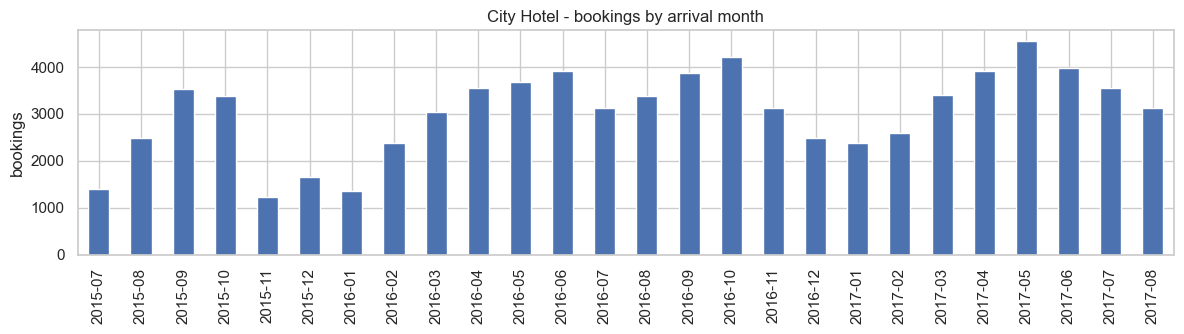

arrival_date,2015-07,2015-08,2015-09,2015-10,2015-11,2015-12,2016-01,2016-02,2016-03,2016-04,2016-05,2016-06,2016-07,2016-08,2016-09,2016-10,2016-11,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08
bookings,"1,398.000","2,480.000","3,529.000","3,386.000","1,235.000","1,654.000","1,364.000","2,371.000","3,046.000","3,561.000","3,676.000","3,923.000","3,131.000","3,378.000","3,871.000","4,219.000","3,122.000","2,478.000","2,372.000","2,594.000","3,412.000","3,919.000","4,556.000","3,971.000","3,559.000","3,125.000"
cancel_rate,0.672,0.497,0.437,0.390,0.244,0.404,0.321,0.392,0.364,0.432,0.391,0.438,0.333,0.369,0.405,0.461,0.436,0.433,0.440,0.374,0.375,0.491,0.487,0.455,0.372,0.359


In [13]:
monthly = df.groupby(df.arrival_date.dt.to_period("M")).agg(
    bookings=("booking_id","size"), cancel_rate=("is_canceled","mean"))
fig, ax = plt.subplots(figsize=(12, 3.5))
monthly["bookings"].plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("City Hotel - bookings by arrival month"); ax.set_xlabel(""); ax.set_ylabel("bookings")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()
monthly.T

### 2.8 Audit findings

- 79,330 rows × 32 columns. Only 4 columns have NaN: `company` 95.4% and `agent` 10.3% (both structural, meaning "none"), `country` 24 rows, `children` 4 rows. Hidden missing: segment "Undefined" (2 rows), channel "Undefined" (4 rows). City Hotel has no `meal = Undefined`.
- **25,902 exact duplicate rows (32.7%).** They come mostly from Groups (44% of duplicates vs 18% of all rows) and Offline TA/TO, 46% are Non Refund, and they cancel at 66% vs 30% for unique rows. This pattern fits **block/group bookings** recorded room by room more than data-entry errors, so dropping them would bias the cancellation rate down. Flag them and run a sensitivity check.
- Validity: 1,208 rows have `adr = 0` (700 outside Complementary), 1 outlier at €5,400, 331 zero-night and 167 zero-guest rows. Status dates are consistent: no cancellation is dated after arrival, and only 6 check-outs don't match arrival + nights.
- Coverage: Jul–Aug 2015 have fewer bookings (hotel data ramp-up). Every month from Sep 2015 to Aug 2017 is complete.

## 3. Data cleaning

Five steps, applied to a copy (`clean`).

| Step | Principle |
|---|---|
| 3.1 Missing values | Structural NaN gets a meaningful value plus a flag; true NaN gets an explicit "unknown" |
| 3.2 Duplicates | Flag, don't drop (likely group/block bookings) |
| 3.3 Formatting & standardisation | Correct types, consistent codes, derived date fields |
| 3.4 Outliers | Rule-based flags for implausible values; IQR only as a diagnostic |
| 3.5 Cross-field & logic validation | Flag contradictory records |

In [14]:
clean = df[["booking_id"] + orig_cols].copy()
flags = pd.DataFrame(index=clean.index)       # one boolean column per data-quality rule
dq_log = []

def log(step, rule, mask_or_n, action, excluded=False):
    n = int(mask_or_n.sum()) if hasattr(mask_or_n, "sum") else int(mask_or_n)
    dq_log.append({"step": step, "rule": rule, "n_rows": n, "pct": n / len(clean) * 100,
                   "action": action, "exclude_from_model": excluded})

def flag(name, mask, step, rule, action, excluded=False):
    flags[name] = mask.fillna(False).astype(bool)
    log(step, rule, flags[name], action, excluded)

### 3.1 Missing values

In [15]:
# Structural NaN: no agent / no company
m = clean.agent.isna();   log("3.1 Missing", "agent NaN (no agent)", m, "has_agent flag; agent_id = 'none'")
m = clean.company.isna(); log("3.1 Missing", "company NaN (no company)", m, "has_company flag; company_id = 'none'")
clean["has_agent"] = clean.agent.notna().astype(int)
clean["has_company"] = clean.company.notna().astype(int)

# True NaN
m = clean.children.isna(); log("3.1 Missing", "children NaN", m, "fill 0")
clean["children"] = clean.children.fillna(0)
m = clean.country.isna();  log("3.1 Missing", "country NaN", m, "fill 'UNK'")
clean["country"] = clean.country.fillna("UNK")

# Hidden missing values
m = clean.meal.eq("Undefined"); log("3.1 Missing", "meal 'Undefined'", m, "map to 'SC' (no meal)")
clean.loc[m, "meal"] = "SC"
flag("undefined_segment_channel",
     clean.market_segment.eq("Undefined") | clean.distribution_channel.eq("Undefined"),
     "3.1 Missing", "market_segment / distribution_channel 'Undefined'", "flag; exclude from model", excluded=True)

assert clean[["children", "country"]].isna().sum().sum() == 0
clean.isna().sum()[lambda s: s > 0]   # only agent / company remain NaN (converted to IDs in 3.3)

agent       8131
company    75641
dtype: int64

### 3.2 Duplicates

In [16]:
dup_key = orig_cols
flag("duplicate_row", clean.duplicated(subset=dup_key, keep="first"),
     "3.2 Duplicates", "exact duplicate of an earlier row (all 32 columns)",
     "flag, keep (likely group/block booking); run sensitivity with/without")

# Block-size PROXY. The key leaves out the outcome columns (is_canceled, reservation_status,
# reservation_status_date, assigned_room_type) and other snapshot-only fields: no outcome column is put
# into the key directly. (Outcomes may still influence snapshot values indirectly.) The remaining attributes (ADR, nights, party, room type, segment, ...) are the
# values in the near-arrival extract, not a booking-time history, so dup_group_size is a retrospective
# proxy: its availability at booking entry or at the end of the booking day is NOT verified.
BLOCK_KEY = ["lead_time", "arrival_date_year", "arrival_date_month", "arrival_date_day_of_month",
             "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies", "meal",
             "market_segment", "distribution_channel", "is_repeated_guest", "previous_cancellations",
             "previous_bookings_not_canceled", "reserved_room_type", "deposit_type", "agent", "company",
             "customer_type", "adr"]
clean["dup_group_size"] = clean.groupby(BLOCK_KEY, dropna=False)["booking_id"].transform("size")
log("3.2 Duplicates", "block-size proxy on reservation attributes (dup_group_size)", clean.dup_group_size.gt(1),
    "retrospective proxy; no outcome columns in key; booking-time availability not verified")
clean["dup_group_size"].value_counts().sort_index().head(10).rename("rows").to_frame()


,rows
dup_group_size,
1,42527
2,8464
3,2373
4,1500
5,975
6,624
7,420
8,584
9,522


- `is_duplicate` (exact copy on all 32 columns) is a **data-quality flag** for sensitivity tests only.
- `dup_group_size` = how many bookings share the same **reservation attributes** in the extract (same arrival date, lead time, stay, party, segment, agent, price…). Large groups (dozens of rows) point to block / allotment bookings, but this is an **inferred proxy**, not a verified group identifier.
- No outcome column is put into the key **directly**, so the target is not copied into it. Outcomes may still influence the snapshot values indirectly. That alone does **not** prove the value was known when the booking was entered: the attributes come from the near-arrival snapshot and may have been revised after booking, and the within-day order of bookings is unknown. Notebook 03 therefore treats `dup_group_size` as a retrospective proxy (basis of the `group_block` population, tested for sensitivity) whose booking-time availability is **not verified**.

### 3.3 Formatting & standardisation

In [17]:
# Integers stored as float
clean["children"] = clean.children.astype(int)

# IDs: float -> string codes ('9.0' -> '9'), 'none' when not applicable
to_id = lambda x: "none" if pd.isna(x) else str(int(x))
clean["agent_id"] = clean.agent.map(to_id)
clean["company_id"] = clean.company.map(to_id)
clean = clean.drop(columns=["agent", "company"])
log("3.3 Format", "agent / company float IDs", len(clean), "convert to string agent_id / company_id")

# Country codes: ISO-3166 alpha-3
m = clean.country.eq("CN"); log("3.3 Format", "country 'CN' (2-letter)", m, "map to 'CHN'")
clean.loc[m, "country"] = "CHN"

# Text fields: strip whitespace (defensive; audit found none)
txt_cols = clean.select_dtypes(include=["object", "string"]).columns
clean[txt_cols] = clean[txt_cols].apply(lambda c: c.str.strip())

# Dates
clean["arrival_month_num"] = clean.arrival_date_month.map({m: i + 1 for i, m in enumerate(MONTHS)})
clean["arrival_date"] = pd.to_datetime(dict(year=clean.arrival_date_year,
                                            month=clean.arrival_month_num,
                                            day=clean.arrival_date_day_of_month))
clean["reservation_status_date"] = pd.to_datetime(clean.reservation_status_date)
clean["booking_date"] = clean.arrival_date - pd.to_timedelta(clean.lead_time, unit="D")
clean["arrival_week_iso"] = clean.arrival_date.dt.isocalendar().week.astype(int)
clean["arrival_dow"] = clean.arrival_date.dt.day_name()
log("3.3 Format", "arrival_date_week_number is non-ISO", len(clean),
    "keep raw; add arrival_week_iso recomputed from arrival_date")

# Derived quantities used everywhere downstream
clean["total_nights"] = clean.stays_in_weekend_nights + clean.stays_in_week_nights
clean["total_guests"] = clean.adults + clean.children + clean.babies

# Categorical dtypes
cat_cols = ["hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
            "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type",
            "reservation_status", "agent_id", "company_id", "arrival_dow"]
clean[cat_cols] = clean[cat_cols].astype("category")
clean.dtypes.to_frame("dtype").T

,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_agent,has_company,dup_group_size,agent_id,company_id,arrival_month_num,arrival_date,booking_date,arrival_week_iso,arrival_dow,total_nights,total_guests
dtype,int64,category,int64,int64,int64,category,int64,int64,int64,int64,int64,int64,int64,category,category,category,category,int64,int64,int64,category,category,int64,category,int64,category,float64,int64,int64,category,datetime64[ns],int64,int64,int64,category,category,int64,datetime64[ns],datetime64[ns],int64,category,int64,int64


### 3.4 Outliers

First an **IQR diagnostic**. Most numeric columns are heavily skewed count variables (mostly 0), so IQR fences flag many legitimate values. They are **not** used to delete or cap anything. The actual decisions use **business-rule thresholds**: a value is flagged only if it is implausible for a city hotel.

In [18]:
iqr_rows = []
for c in num_cols:
    q1, q3 = clean[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({"column": c, "q1": q1, "q3": q3, "upper_fence": hi,
                     "n_above_fence": int((clean[c] > hi).sum()), "max": clean[c].max()})
pd.DataFrame(iqr_rows).set_index("column")

,q1,q3,upper_fence,n_above_fence,max
column,,,,,
lead_time,23.000,163.000,373.000,2576,629.000
stays_in_weekend_nights,0.000,2.000,5.000,82,16.000
stays_in_week_nights,1.000,3.000,6.000,719,41.000
adults,2.000,2.000,2.000,4806,4.000
children,0.000,0.000,0.000,5106,3.000
babies,0.000,0.000,0.000,369,10.000
previous_cancellations,0.000,0.000,0.000,5389,21.000
previous_bookings_not_canceled,0.000,0.000,0.000,1588,72.000
booking_changes,0.000,0.000,0.000,10268,21.000


In [19]:
# Business-rule outlier flags (thresholds are documented assumptions)
flag("adr_error", clean.adr > 1000, "3.4 Outliers", "adr > 1000 EUR",
     "data error: set adr_clean = NaN; exclude from model", excluded=True)
flag("adr_zero_paid_segment", (clean.adr == 0) & (clean.market_segment != "Complementary"),
     "3.4 Outliers", "adr == 0 outside Complementary", "flag; exclude from revenue KPIs")
flag("long_stay", clean.total_nights > 30, "3.4 Outliers", "total_nights > 30",
     "flag (plausible long stay); keep")
flag("babies_extreme", clean.babies > 3, "3.4 Outliers", "babies > 3 in one booking",
     "likely entry error; exclude from model", excluded=True)
flag("extreme_lead_time", clean.lead_time > 540, "3.4 Outliers", "lead_time > 540 days (~18 months)",
     "flag; keep (plausible advance group booking)")

clean["adr_clean"] = clean.adr.where(~flags.adr_error)
clean["gross_value"] = (clean.adr_clean.clip(lower=0) * clean.total_nights).fillna(0)
flags.sum().rename("n_flagged").to_frame()

,n_flagged
undefined_segment_channel,4
duplicate_row,25902
adr_error,1
adr_zero_paid_segment,700
long_stay,7
babies_extreme,2
extreme_lead_time,281


### 3.5 Cross-field & logic validation

In [20]:
flag("zero_guests", clean.total_guests == 0, "3.5 Logic", "0 adults, 0 children, 0 babies",
     "impossible booking; exclude from model", excluded=True)
flag("zero_nights", clean.total_nights == 0, "3.5 Logic", "0 total nights",
     "day-use/data error; exclude from model and room-night KPIs", excluded=True)
flag("no_adult", (clean.adults == 0) & (clean.total_guests > 0), "3.5 Logic",
     "children/babies but no adult", "flag; keep")
flag("repeat_no_history",
     (clean.is_repeated_guest == 1) & (clean.previous_cancellations + clean.previous_bookings_not_canceled == 0),
     "3.5 Logic", "is_repeated_guest = 1 but no previous bookings",
     "flag; keep (history may predate the PMS extract)")
flag("complementary_paid", (clean.market_segment == "Complementary") & (clean.adr > 0),
     "3.5 Logic", "Complementary segment with adr > 0", "flag; keep")
flag("segment_channel_mismatch",
     ((clean.market_segment == "Direct") & (clean.distribution_channel != "Direct")) |
     ((clean.market_segment == "Corporate") & (clean.distribution_channel == "TA/TO")) |
     ((clean.market_segment.isin(["Online TA", "Offline TA/TO"])) & (clean.distribution_channel == "Direct")),
     "3.5 Logic", "market_segment inconsistent with distribution_channel", "flag; keep")
flag("checkout_date_mismatch",
     (clean.reservation_status == "Check-Out") &
     (clean.reservation_status_date != clean.arrival_date + pd.to_timedelta(clean.total_nights, unit="D")),
     "3.5 Logic", "Check-Out date != arrival + nights", "flag; keep")
flag("cancel_after_arrival",
     (clean.reservation_status == "Canceled") & (clean.reservation_status_date > clean.arrival_date),
     "3.5 Logic", "cancellation dated after arrival", "flag; exclude", excluded=True)
flag("cancel_before_booking",
     (clean.reservation_status == "Canceled") & (clean.reservation_status_date < clean.booking_date),
     "3.5 Logic", "cancellation dated before booking date", "flag; exclude", excluded=True)

# Target consistency must hold exactly
target_ok = (clean.is_canceled.eq(1) == clean.reservation_status.isin(["Canceled", "No-Show"])).all()
log("3.5 Logic", "is_canceled consistent with reservation_status", 0 if target_ok else 1, "assert")
assert target_ok
flags.sum().rename("n_flagged").to_frame()

,n_flagged
undefined_segment_channel,4
duplicate_row,25902
adr_error,1
adr_zero_paid_segment,700
long_stay,7
babies_extreme,2
extreme_lead_time,281
zero_guests,167
zero_nights,331
no_adult,223


### 3.6 Consolidate flags, cleaning log and export

In [21]:
excluded_rules = [r["rule"] for r in dq_log if r["exclude_from_model"]]
exclude_cols = ["undefined_segment_channel", "adr_error", "babies_extreme", "zero_guests",
                "zero_nights", "cancel_after_arrival", "cancel_before_booking"]

clean["is_duplicate"] = flags.duplicate_row.astype(int)
clean["exclude_from_model"] = flags[exclude_cols].any(axis=1)

dq_report = pd.DataFrame(dq_log)
print(f"Rows in cleaned file      : {len(clean):,} (nothing dropped)")
print(f"Rows with >=1 flag        : {flags.any(axis=1).sum():,}")
print(f"Rows excluded from model  : {clean.exclude_from_model.sum():,} ({clean.exclude_from_model.mean():.2%})")
print(f"Modelling rows            : {(~clean.exclude_from_model).sum():,}")
dq_report

Rows in cleaned file      : 79,330 (nothing dropped)
Rows with >=1 flag        : 27,136
Rows excluded from model  : 438 (0.55%)
Modelling rows            : 78,892


,step,rule,n_rows,pct,action,exclude_from_model
0,3.1 Missing,agent NaN (no agent),8131,10.250,has_agent flag; agent_id = 'none',False
1,3.1 Missing,company NaN (no company),75641,95.350,has_company flag; company_id = 'none',False
2,3.1 Missing,children NaN,4,0.005,fill 0,False
3,3.1 Missing,country NaN,24,0.030,fill 'UNK',False
4,3.1 Missing,meal 'Undefined',0,0.000,map to 'SC' (no meal),False
5,3.1 Missing,market_segment / distribution_channel 'Undefined',4,0.005,flag; exclude from model,True
6,3.2 Duplicates,exact duplicate of an earlier row (all 32 colu...,25902,32.651,"flag, keep (likely group/block booking); run s...",False
7,3.2 Duplicates,block-size proxy on reservation attributes (du...,36803,46.392,retrospective proxy; no outcome columns in key...,False
8,3.3 Format,agent / company float IDs,79330,100.000,convert to string agent_id / company_id,False
9,3.3 Format,country 'CN' (2-letter),569,0.717,map to 'CHN',False


In [22]:
col_order = (["booking_id", "hotel", "is_canceled", "reservation_status", "reservation_status_date",
              "booking_date", "arrival_date", "lead_time"]
             + [c for c in clean.columns if c not in
                {"booking_id", "hotel", "is_canceled", "reservation_status", "reservation_status_date",
                 "booking_date", "arrival_date", "lead_time", "is_duplicate", "exclude_from_model"}]
             + ["is_duplicate", "exclude_from_model"])
clean = clean[col_order]

# ---- Column groups --------------------------------------------
ID_TARGET = ["booking_id", "is_canceled"]

# Dropped from the exported file: constant, redundant, or suspected leakage with no ops use
DROP_COLS = {
    "hotel": "constant after filtering to City Hotel",
    "arrival_date_week_number": "non-ISO and redundant -> use arrival_week_iso",
    "arrival_date_year": "redundant with arrival_date",
    "arrival_date_month": "redundant -> use arrival_month_num",
    "arrival_date_day_of_month": "redundant with arrival_date",
    "company_id": "95% 'none', 207 IDs -> keep has_company",
    "adr": "raw value contains a data error -> use adr_clean",
    "required_car_parking_spaces": "suspected leakage (0% cancellation), no room/revenue use",
}

# Kept for analysis and operations (capacity, resale, pricing, CX) but NEVER model features
OPS_ONLY_COLS = [
    "reservation_status", "reservation_status_date",   # outcome: cancellation timing / resale window
    "assigned_room_type",                               # may change until check-in (allocation time unknown): capacity & upgrades
    "country",                                          # booking-time value not verified (strong PRT association); fairness; CX use
    "arrival_date", "booking_date",                     # keys for time split and stay-night expansion
    "gross_value",                                      # money (adr_clean x nights)
    "is_duplicate", "exclude_from_model",               # data-quality flags
]

# Candidate columns kept in the cleaned file for modelling work (NOT the final training lists).
# The final, time-aware feature lists per population are built in notebook 03
# (config/column_groups.json -> individual_model / group_model).
NB01_CANDIDATE_COLUMNS = [
    # booking & stay
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "total_nights",
    "adults", "children", "babies", "total_guests", "meal", "reserved_room_type",
    "arrival_month_num", "arrival_week_iso", "arrival_dow",
    # commercial
    "market_segment", "distribution_channel", "deposit_type", "customer_type", "adr_clean",
    "agent_id", "has_agent", "has_company", "dup_group_size",
    # guest history & engagement
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "total_of_special_requests",
    # use with caveat: snapshot taken the day before arrival
    "booking_changes", "days_in_waiting_list",
]

export = clean.drop(columns=list(DROP_COLS))
groups = ID_TARGET + OPS_ONLY_COLS + NB01_CANDIDATE_COLUMNS
assert len(groups) == len(set(groups))
assert set(groups) == set(export.columns), set(groups) ^ set(export.columns)

summary = pd.DataFrame(
    [(c, "dropped", r) for c, r in DROP_COLS.items()]
    + [(c, "id / target", "") for c in ID_TARGET]
    + [(c, "ops only (not a feature)", "") for c in OPS_ONLY_COLS]
    + [(c, "candidate (NB01)", "day-before-arrival snapshot / cumulative" if c in ("booking_changes", "days_in_waiting_list", "total_of_special_requests") else "")
       for c in NB01_CANDIDATE_COLUMNS],
    columns=["column", "group", "note"])
display(summary.group.value_counts().to_frame("n_columns"))

OUT_DIR = ROOT / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)
export.to_csv(OUT_DIR / "bookings_city_clean.csv", index=False, date_format="%Y-%m-%d")

import json
(ROOT / "config").mkdir(exist_ok=True)
with open(ROOT / "config" / "column_groups.json", "w") as f:
    json.dump({"id_target": ID_TARGET, "nb01_candidate_columns": NB01_CANDIDATE_COLUMNS,
               "ops_only_cols": OPS_ONLY_COLS, "dropped": DROP_COLS}, f, indent=2)

print("Saved:", OUT_DIR / "bookings_city_clean.csv", export.shape)
print("Saved:", ROOT / "config" / "column_groups.json")
summary

,n_columns
group,
candidate (NB01),28
ops only (not a feature),9
dropped,8
id / target,2


Saved: C:\Users\ADMIN\Desktop\AAA\BA-Advance-Project---Group-2-main\data\processed\bookings_city_clean.csv (79330, 39)
Saved: C:\Users\ADMIN\Desktop\AAA\BA-Advance-Project---Group-2-main\config\column_groups.json


,column,group,note
0,hotel,dropped,constant after filtering to City Hotel
1,arrival_date_week_number,dropped,non-ISO and redundant -> use arrival_week_iso
2,arrival_date_year,dropped,redundant with arrival_date
3,arrival_date_month,dropped,redundant -> use arrival_month_num
4,arrival_date_day_of_month,dropped,redundant with arrival_date
5,company_id,dropped,"95% 'none', 207 IDs -> keep has_company"
6,adr,dropped,raw value contains a data error -> use adr_clean
7,required_car_parking_spaces,dropped,"suspected leakage (0% cancellation), no room/r..."
8,booking_id,id / target,
9,is_canceled,id / target,


**Notes for downstream users:**
- `nb01_candidate_columns` in `config/column_groups.json` is only the list of non-outcome columns kept in the cleaned file. It is **not** a training list. The final, time-aware feature lists per population are built in notebook 03 (`config/column_groups.json` → `individual_model`, `group_model`). Ops-only columns stay in the file for capacity, resale and CX analysis but are **never** features.
- Use `adr_clean` / `gross_value` for money. The modelling population is `exclude_from_model == False` (notebook 03 applies this filter; `modeling_dataset.csv` is already filtered). Report results with and without `is_duplicate == 1`.
- Read back with `parse_dates=["arrival_date", "booking_date", "reservation_status_date"]`.

In [23]:
# From here on, EDA uses the cleaned data
df = clean.copy()

## 4. Preliminary EDA

Focus: **how much** the hotel loses to cancellations and **which booking attributes** are associated with them. These are associations, not causal effects.

In [24]:
def rate_table(col, data=df, order=None, min_n=0):
    t = data.groupby(col, observed=True).agg(n=("is_canceled","size"), cancel_rate=("is_canceled","mean"))
    t["share"] = t["n"] / t["n"].sum()
    t = t[t["n"] >= min_n]
    return t.reindex(order) if order is not None else t.sort_values("cancel_rate", ascending=False)

def plot_rate(t, title, ax=None):
    ax = ax or plt.gca()
    t["cancel_rate"].plot(kind="barh", ax=ax, color="#C44E52")
    ax.axvline(df.is_canceled.mean(), ls="--", c="grey", lw=1, label="overall")
    ax.set_xlim(0, 1); ax.set_title(title); ax.set_xlabel("cancellation rate"); ax.set_ylabel("")
    for i, (r, n) in enumerate(zip(t["cancel_rate"], t["n"])):
        ax.text(r + 0.01, i, f"{r:.0%} (n={n:,})", va="center", fontsize=8)
    ax.invert_yaxis()

### 4.1 Overall cancellation and revenue exposure

In [25]:
overview = pd.Series({
    "bookings": len(df),
    "cancellation rate (incl. no-show)": df.is_canceled.mean(),
    "  - canceled": (df.reservation_status=="Canceled").mean(),
    "  - no-show":  (df.reservation_status=="No-Show").mean(),
    "booked room-nights": df.total_nights.sum(),
    "cancelled room-nights": df.loc[df.is_canceled==1, "total_nights"].sum(),
    "gross booked value (EUR)": df.gross_value.sum(),
    "gross value of cancelled bookings (EUR)": df.loc[df.is_canceled==1, "gross_value"].sum(),
})
overview["share of value cancelled"] = overview["gross value of cancelled bookings (EUR)"] / overview["gross booked value (EUR)"]
overview.to_frame("value")

,value
bookings,"79,330.000"
cancellation rate (incl. no-show),0.417
- canceled,0.406
- no-show,0.012
booked room-nights,"236,256.000"
cancelled room-nights,"101,103.000"
gross booked value (EUR),"25,274,069.960"
gross value of cancelled bookings (EUR),"10,879,659.780"
share of value cancelled,0.430


> Gross value = `adr × nights`, before commission and cost, and **before any resale**. It is an upper bound on exposure, not the actual loss. Measuring the real loss needs data the dataset does not have (see Section 5).

### 4.2 Lead time

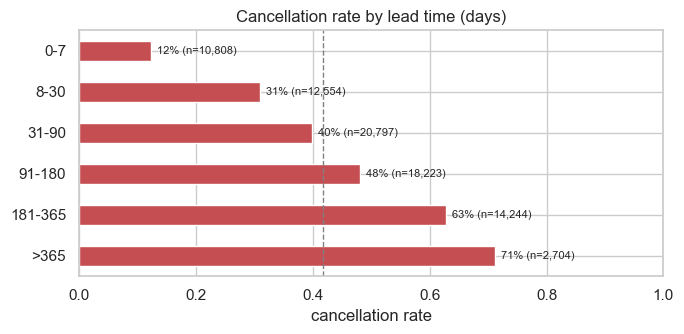

In [26]:
bins = [-1, 7, 30, 90, 180, 365, 10_000]
labels = ["0-7", "8-30", "31-90", "91-180", "181-365", ">365"]
df["lead_time_bucket"] = pd.cut(df.lead_time, bins=bins, labels=labels)
plt.figure(figsize=(7, 3.5))
plot_rate(rate_table("lead_time_bucket", order=labels), "Cancellation rate by lead time (days)")
plt.tight_layout(); plt.show()

### 4.3 Commercial attributes: deposit, segment, channel, customer type

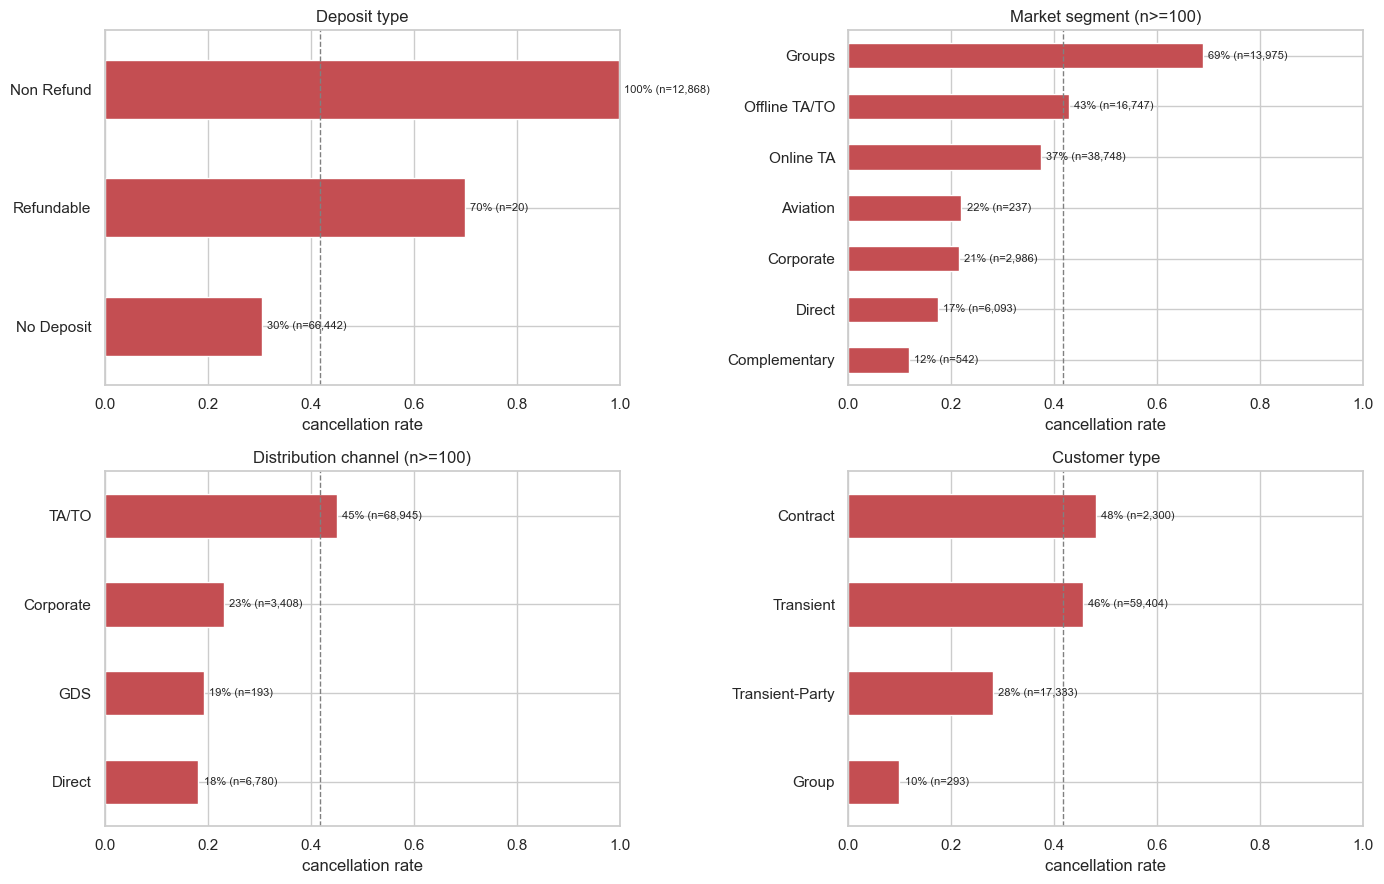

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_rate(rate_table("deposit_type"), "Deposit type", axes[0, 0])
plot_rate(rate_table("market_segment", min_n=100), "Market segment (n>=100)", axes[0, 1])
plot_rate(rate_table("distribution_channel", min_n=100), "Distribution channel (n>=100)", axes[1, 0])
plot_rate(rate_table("customer_type"), "Customer type", axes[1, 1])
plt.tight_layout(); plt.show()

### 4.4 Cancellation timing: how much notice does the hotel get?

For **revenue recovery**, *when* a booking is cancelled matters as much as *whether*. The earlier the notice, the better the chance to resell. We use `reservation_status_date` here **for analysis only** (never as a feature).

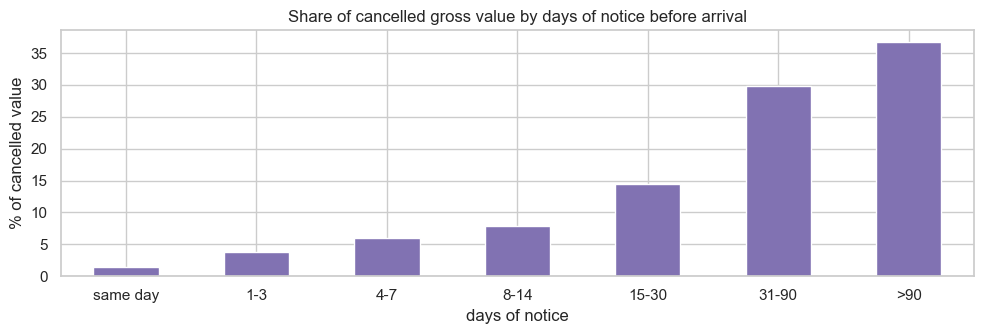

No-shows (0 notice, not resellable): 916


,cancellations,room_nights,gross_value,pct_cancellations,pct_value
notice_bucket,,,,,
same day,555,1435,"143,997.620",1.724,1.369
1-3,1342,3818,"395,819.210",4.170,3.763
4-7,1973,5611,"627,345.760",6.130,5.964
8-14,2381,7372,"823,099.630",7.398,7.825
15-30,4347,13618,"1,523,173.530",13.506,14.481
31-90,9534,29489,"3,142,888.770",29.622,29.880
>90,12054,36257,"3,862,165.120",37.451,36.718


In [28]:
canc = df[df.reservation_status == "Canceled"].copy()
canc["days_notice"] = (canc.arrival_date - canc.reservation_status_date).dt.days
notice_bins = [-1, 0, 3, 7, 14, 30, 90, 10_000]
notice_labels = ["same day", "1-3", "4-7", "8-14", "15-30", "31-90", ">90"]
canc["notice_bucket"] = pd.cut(canc.days_notice, notice_bins, labels=notice_labels)

notice = canc.groupby("notice_bucket", observed=True).agg(
    cancellations=("booking_id","size"), room_nights=("total_nights","sum"), gross_value=("gross_value","sum"))
notice["pct_cancellations"] = notice.cancellations / notice.cancellations.sum() * 100
notice["pct_value"] = notice.gross_value / notice.gross_value.sum() * 100

fig, ax = plt.subplots(figsize=(10, 3.5))
notice["pct_value"].plot(kind="bar", ax=ax, color="#8172B2")
ax.set_title("Share of cancelled gross value by days of notice before arrival")
ax.set_ylabel("% of cancelled value"); ax.set_xlabel("days of notice"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print("No-shows (0 notice, not resellable):", (df.reservation_status=="No-Show").sum())
notice

### 4.5 Preliminary EDA findings
1. **Scale:** 41.7% of bookings don't arrive (40.6% cancelled + 1.2% no-show). That is 101k of 236k room-nights and **€10.9M (43.0%) of €25.3M** gross booked value.
2. **Lead time is the clearest driver:** 12% cancellation at 0–7 days vs 71% beyond a year.
3. **Commercial mix:** Groups (69%) and Offline TA/TO (43%) are the riskiest segments, Direct (17%) the safest. **Non Refund cancels ~100%**, a pattern consistent with block/allotment bookings rather than individual guests (inferred, not verified). Notebook 03 therefore models it as a separate `group_block` population.
4. **Recovery window:** 81% of cancelled value is cancelled ≥15 days before arrival (median 58 days), so most of it is resellable in principle. ~11% comes with ≤7 days notice, plus 916 no-shows that can't be resold. Two levers follow: early contact for high-risk, long-lead bookings, and resale / controlled overbooking for the rest.

## 5. Data gap analysis: what is missing to optimise revenue and occupancy

The business goal is to **optimise revenue and room occupancy**: predict cancellation risk, handle bookings proactively (follow-up, price adjustment, capacity allocation, resale), and automate interventions with staff approval. Below, each decision in the PDMT workflow is mapped to the data it needs and what the dataset actually provides.

In [29]:
gap = pd.DataFrame([
    # (decision, data needed, available in dataset, gap, how we fill it)
    ("Predict cancellation risk", "Booking attributes, guest history, channel, price, lead time",
     "Yes", "Features are a day-before-arrival snapshot, not the state at earlier decision points",
     "Use as-is; note limitation; avoid leaky fields"),
    ("Predict cancellation risk", "Unique booking / guest ID", "No",
     "No key; duplicates are ambiguous; no linking to guest", "booking_id = sequential ID 1..79,330 assigned after filtering"),
    ("Value at risk (net)", "Room cost per night", "No", "Only revenue (adr) exists",
     "Synthetic: room_cost_per_night"),
    ("Value at risk (net)", "Channel commission", "Partial",
     "Channel/segment known, commission rate unknown", "Synthetic: channel_commission_rate"),
    ("Value at risk (net)", "Cancellation penalty / fee actually charged", "No",
     "deposit_type only; no amount retained", "Assumption by deposit type (team assumption)"),
    ("Cost of cancellation", "Cost to process a cancellation", "No", "Not recorded",
     "Synthetic: cancellation_handling_cost"),
    ("Choose intervention", "Whether / how the guest was contacted, and the response", "No",
     "No CRM or contact log", "Synthetic: contact_attempted, contact_channel, customer_response"),
    ("Choose intervention", "Reason for cancellation", "No", "Not captured",
     "Synthetic: cancellation_reason (category + text)"),
    ("Timing of intervention", "Cancellation date", "Yes (analysis only)",
     "reservation_status_date = last status date; outcome-derived", "Use for notice-period analysis only"),
    ("Capacity allocation", "Room inventory per date x room type", "No",
     "No capacity; peak occupancy is only a lower bound", "Synthetic/assumed: available_rooms (date x room type)"),
    ("Capacity allocation", "Rooms sold per date x room type", "Derivable",
     "Rebuilt from non-cancelled stay nights x assigned_room_type", "rooms_sold derived from data"),
    ("Capacity allocation", "Real-time inventory updates", "No",
     "Static extract, no PMS feed", "Prototype: ops table in PostgreSQL updated by n8n"),
    ("Resale", "Whether a cancelled room was resold, and at what price", "No",
     "Not recorded", "Synthetic: resold_after_cancellation, rebooking_revenue"),
    ("Price adjustment", "Historical price by date x room type x segment", "Derivable",
     "adr_clean per booking can be aggregated", "Derive ADR curves from data"),
    ("Price adjustment", "Demand on the books / pickup, competitor prices, price elasticity", "No",
     "No forward-looking demand or market data", "Proxy via lead time, season, occupancy; elasticity as team assumption"),
    ("Evaluate CX impact", "Guest satisfaction", "No", "Not captured",
     "Synthetic: satisfaction_score (post-stay, never a feature)"),
    ("Evaluate strategy", "Outcomes of past interventions (uplift)", "No",
     "No historical interventions", "Scenario assumptions + pilot design with holdout"),
], columns=["decision","data_needed","in_dataset","gap","how_we_fill"])
gap

,decision,data_needed,in_dataset,gap,how_we_fill
0,Predict cancellation risk,"Booking attributes, guest history, channel, pr...",Yes,"Features are a day-before-arrival snapshot, no...",Use as-is; note limitation; avoid leaky fields
1,Predict cancellation risk,Unique booking / guest ID,No,No key; duplicates are ambiguous; no linking t...,"booking_id = sequential ID 1..79,330 assigned ..."
2,Value at risk (net),Room cost per night,No,Only revenue (adr) exists,Synthetic: room_cost_per_night
3,Value at risk (net),Channel commission,Partial,"Channel/segment known, commission rate unknown",Synthetic: channel_commission_rate
4,Value at risk (net),Cancellation penalty / fee actually charged,No,deposit_type only; no amount retained,Assumption by deposit type (team assumption)
5,Cost of cancellation,Cost to process a cancellation,No,Not recorded,Synthetic: cancellation_handling_cost
6,Choose intervention,"Whether / how the guest was contacted, and the...",No,No CRM or contact log,"Synthetic: contact_attempted, contact_channel,..."
7,Choose intervention,Reason for cancellation,No,Not captured,Synthetic: cancellation_reason (category + text)
8,Timing of intervention,Cancellation date,Yes (analysis only),reservation_status_date = last status date; ou...,Use for notice-period analysis only
9,Capacity allocation,Room inventory per date x room type,No,No capacity; peak occupancy is only a lower bound,Synthetic/assumed: available_rooms (date x roo...


In [30]:
# Coverage summary: how much of the required data the original dataset provides
gap["in_dataset_simple"] = gap.in_dataset.str.extract(r"^(Yes|No|Partial|Derivable)")[0]
gap.groupby("in_dataset_simple").size().rename("n_requirements").to_frame()

,n_requirements
in_dataset_simple,
Derivable,2
No,12
Partial,1
Yes,2


### 5.1 Gap analysis conclusions

1. The dataset is **strong for predicting** cancellations (rich booking attributes, a clean target) but **weak for optimising revenue and occupancy**: it has revenue but no cost, commission, room inventory, resale or market-demand data.
2. The missing data falls into the three domains of the data architecture: **CX** (contact and reason), **Finance** (cost and recovered revenue) and **Operations** (capacity by room type, inventory and resale). This justifies the 12 synthetic columns.
3. Synthetic values must be grounded in **Lisbon 2015–2017** conditions or derived from this data, recorded in `config/assumptions.yaml`, and stress-tested in scenarios.
4. Two limitations to state in the report: (a) features are a day-before-arrival snapshot; (b) intervention uplift can't be measured from history and needs a pilot with a holdout group.

**Next:** notebook 02 builds the synthetic tables that fill these gaps.